## Домашнее задание

Что день грядущий нам готовит? Построение прогноза временного ряда с использованием изученных методов

### Цель:

В этом домашнем задании будем заниматься очень интересными прогнозами, которые вполне могут быть полезны для организации работы метро — попробуем построить модель, которая предсказывает, сколько пассажиров будут им пользоваться в ближайшее время.


Описание/Пошаговая инструкция выполнения домашнего задания:

### Подготовка:

Скачиваем данные по загруженности метро вот отсюда https://archive.ics.uci.edu/ml/datasets/Metro+Interstate+Traffic+Volume

Проводим базовый EDA, вам понадобятся только 4 столбца датасета - traffic_volume (наша целевая переменная), date_time, holiday (является ли день некоторым праздником) и temp (температура воздуха).

По результатам EDA убеждаемся, что в этом временном ряду во-первых, есть дубликаты, а во-вторых, нарушена равномерность временных интервалов, т.е. не все значения отстоят друг от друга на 1 час - дубликаты удаляем, а временные интервалы выравниваем и заполняем пропуски при помощи линейной интерполяции (подсказка - в этом вам помогут функции pd.date_range, и interpolate, пример можно найти здесь - https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.interpolate.html).

In [1]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_error
import pickle

from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA, AutoTBATS

import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv('Metro_Interstate_Traffic_Volume.csv')

In [3]:
df.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [4]:
df.describe()

,temp,rain_1h,snow_1h,clouds_all,traffic_volume
count,48204.000000,48204.000000,48204.000000,48204.000000,48204.000000
mean,281.205870,0.334264,0.000222,49.362231,3259.818355
std,13.338232,44.789133,0.008168,39.015750,1986.860670
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,272.160000,0.000000,0.000000,1.000000,1193.000000
50%,282.450000,0.000000,0.000000,64.000000,3380.000000
75%,291.806000,0.000000,0.000000,90.000000,4933.000000
max,310.070000,9831.300000,0.510000,100.000000,7280.000000


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     object 
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  object 
 6   weather_description  48204 non-null  object 
 7   date_time            48204 non-null  object 
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), object(4)
memory usage: 3.3+ MB


In [6]:
df = df[['traffic_volume', 'date_time', 'holiday', 'temp']]

In [7]:
df['date_time'] = pd.to_datetime(df['date_time'])

In [8]:
df.nunique()

traffic_volume     6704
date_time         40575
holiday              11
temp               5843
dtype: int64

Построим график значений трафика 

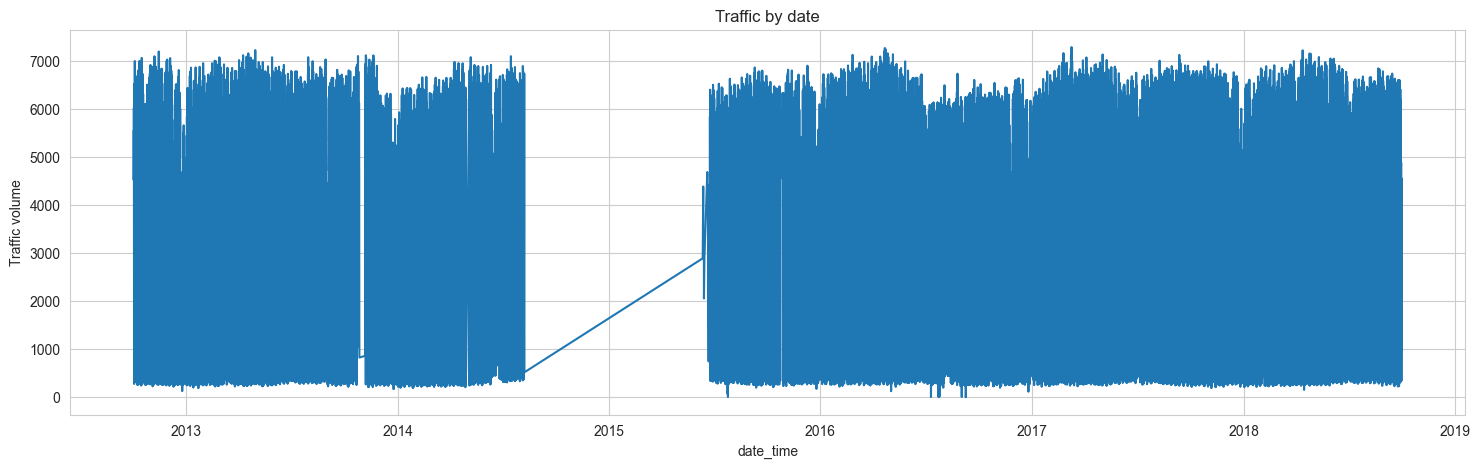

In [9]:
sns.set_style("whitegrid")
plt.figure(figsize = (18, 5))
res = sns.lineplot(data = df[:], x='date_time', y='traffic_volume')
res.set_ylabel('Traffic volume')
res.set_title('Traffic by date')
plt.show()

С середины 2014 года по середину 2015 значительный пробел в данных. Учитывая выбросы в 2016 году будем использовать использовать данные с 2018 года.

In [10]:
df = df[df['date_time'].dt.year>=2018]

Уберем дубликаты в date_time

In [11]:
df = df[df['date_time'].duplicated()==False].sort_values('date_time')

In [12]:
df = df.set_index('date_time').asfreq('1h')

Проведем интерполяцию traffic_volume и temp

In [13]:
df['traffic_volume'] = df['traffic_volume'].astype('float')

In [14]:
df[['temp','traffic_volume']] = df[['temp','traffic_volume']].interpolate(method='linear')

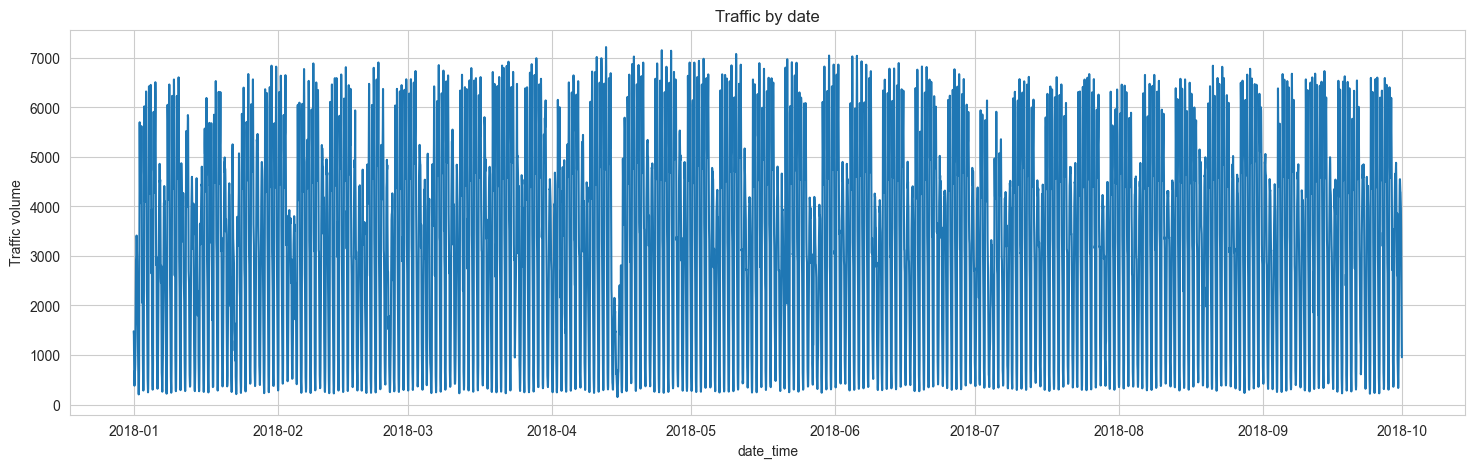

In [15]:
sns.set_style("whitegrid")
plt.figure(figsize = (18,5))
res = sns.lineplot(data = df[:], x='date_time', y='traffic_volume')
res.set_ylabel('Traffic volume')
res.set_title('Traffic by date')
plt.show()

### Моделирование:

Теперь, когда ряд выглядит более-менее адекватно, настало время прогнозировать. Нашей целью будет построить модель, которая способна прогнозировать загрузку метро на ближайшую неделю (т.е, так как данные у нас дневные, модель должна предсказывать на 24*7 точек вперёд).

Отложите последние две недели в датасете для тестирования вашей модели - на этих данных вы будете проверять финальное качество всех моделек.

Теперь у вас осталось еще много-много наблюдений во временном ряду, исходя из графиков, трендов и т.д., попробуйте предположить, какие исторические данные действительно будут релевантны для прогнозов текущих значений, возможно, предыдущие три года уже не так сильно влияют на следующую неделю и можно значительную часть данных просто выкинуть.

Генерируем дополнительные признаки из индекса, особенно нужен день недели и час дня.

Строим baseline прогноз - по тем данным, которые вы решили оставить для обучения модели, посчитайте средние значения по часам и по дням (вам поможет data.groupby(["weekday", "hour"])["traffic_volume"].mean() и используйте эти значения в качестве прогноза на отложенную выборку - посчитайте метрики качества, которые вы посчитаете нужными.

А теперь свободное творчество - попробуйте построить разные модели, которые мы с вами разбирали, и побить качество базового прогноза.

### Несколько советов:

для SARIMA модели имеет смысл указать недельную сезонность (т.е. 24*7), чтобы она учла падения по выходным;

попробуйте использовать температуру воздуха, как признак, в этом случае можно отдельно спрогнозировать температуру (например, используя SARIMA), а затем воспользоваться этими предсказаниями, когда будете делать прогноз для отложенной части выборки.

Наконец, когда вы подберете модель, устраивающую вас по качеству на отложенной выборке, используйте эту выборку для построения прогноза на следующую неделю и попробуйте построить доверительные интервалы для этого прогноза.

Теперь вы круто разбираетесь в прогнозировании и временных рядах :)

### Критерии оценки:
- Базовый EDA - 2 балла.

- Генерация дополнительных признаков - 2 балла.

- Baseline прогноз и проверка качества - 1 балл.

- Построение различных моделей - 5 баллов.

Генерируем дополнительные признаки

In [16]:
df['year'] = df.index.year
df['month'] = df.index.month
df.reset_index(inplace=True)
df['week'] = df['date_time'].dt.isocalendar().week
df['hour'] = df['date_time'].dt.hour
df['weekday'] = df['date_time'].dt.dayofweek
df['day_str'] = df['date_time'].dt.strftime('%a')
df['year_month'] = df['date_time'].dt.strftime('%Y_%m')
df.set_index('date_time', inplace=True)
df

,traffic_volume,holiday,temp,year,month,week,hour,weekday,day_str,year_month
date_time,,,,,,,,,,
2018-01-01 00:00:00,1478.0,New Years Day,249.36,2018,1,1,0,0,Mon,2018_01
2018-01-01 01:00:00,1408.0,NaN,249.08,2018,1,1,1,0,Mon,2018_01
2018-01-01 02:00:00,931.0,NaN,248.86,2018,1,1,2,0,Mon,2018_01
2018-01-01 03:00:00,585.0,NaN,248.72,2018,1,1,3,0,Mon,2018_01
2018-01-01 04:00:00,381.0,NaN,248.43,2018,1,1,4,0,Mon,2018_01
...,...,...,...,...,...,...,...,...,...,...
2018-09-30 19:00:00,3543.0,NaN,283.45,2018,9,39,19,6,Sun,2018_09
2018-09-30 20:00:00,2781.0,NaN,282.76,2018,9,39,20,6,Sun,2018_09
2018-09-30 21:00:00,2159.0,NaN,282.73,2018,9,39,21,6,Sun,2018_09


In [17]:
test_size = 24*7
train, test = df[:-test_size], df[-test_size:]

Разложение ETS для разделения различных компонентов временного ряда

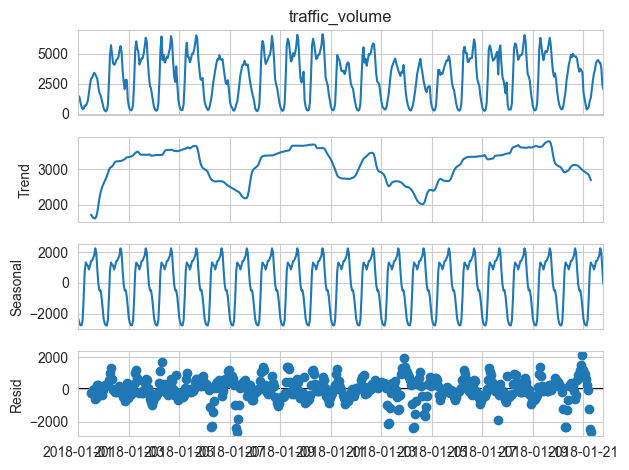

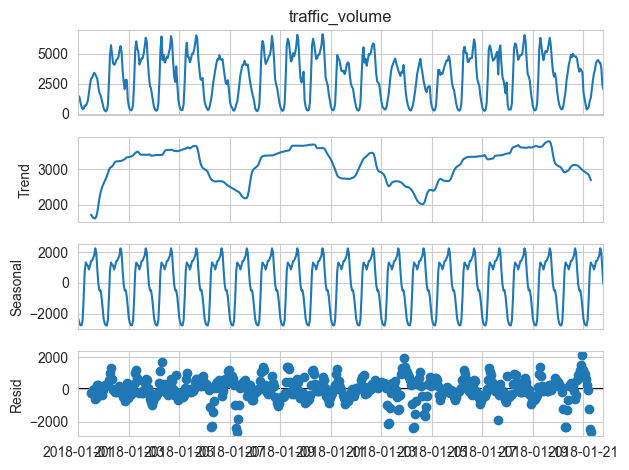

In [18]:
from statsmodels.tsa.seasonal import seasonal_decompose

# ETS Decomposition
result = seasonal_decompose(train['traffic_volume'][:500], model="additive", period=24)

# ETS plot 
result.plot()

Проверка стационарности

In [19]:
def check_stationarity(timeseries):
    result = adfuller(timeseries.dropna())
    print('ADF Statistic:', result[0])
    print('p-value:', result[1])
    print('Critical Values:')
    for key, value in result[4].items():
        print(f'\t{key}: {value}')

    if result[1] <= 0.05:
        print("Ряд стационарен (отвергаем H0)")
        return True
    else:
        print("Ряд нестационарен (не отвергаем H0)")
        return False

print("Проверка стационарности исходного ряда:")
is_stationary = check_stationarity(df['traffic_volume'])

Проверка стационарности исходного ряда:
ADF Statistic: -10.633215080874828
p-value: 5.150454169266595e-19
Critical Values:
	1%: -3.431353663270874
	5%: -2.8619835333734627
	10%: -2.567006089438542
Ряд стационарен (отвергаем H0)


Строим baseline прогноз

In [20]:
baseline = train.groupby(["weekday", "hour"],)["traffic_volume"].mean()

In [21]:
baseline

weekday  hour
0        0        660.657895
         1        409.315789
         2        313.657895
         3        359.973684
         4        834.473684
                    ...     
6        19      3107.526316
         20      2831.473684
         21      2484.578947
         22      1860.315789
         23      1222.710526
Name: traffic_volume, Length: 168, dtype: float64

In [22]:
def print_errors(y, y_pred):
    mae = mean_absolute_error(y, y_pred )
    rmse = np.sqrt(mean_squared_error(y, y_pred ))
    print(f'Mean Absolute Error: {mae:.2f}')
    print(f'Root Mean Squared Error: {rmse:.2f}')

In [23]:
print_errors(test['traffic_volume'], baseline)

Mean Absolute Error: 191.85
Root Mean Squared Error: 299.89


### Построение различных моделей

#### АRIMA

Подбор оптимальных параметров

In [24]:
# Функция для подбора оптимальных параметров ARIMA по критерию Акаике
def find_best_arima(train_data, max_p=5, max_d=2, max_q=5):
    best_aic = np.inf
    best_order = None
    best_model = None

    for p in range(max_p + 1):
        for d in range(max_d + 1):
            for q in range(max_q + 1):
                try:
                    model = ARIMA(train_data, order=(p, d, q))
                    fitted_model = model.fit()

                    if fitted_model.aic < best_aic:
                        best_aic = fitted_model.aic
                        best_order = (p, d, q)
                        best_model = fitted_model

                    print(f'ARIMA({p},{d},{q}) - AIC: {fitted_model.aic:.2f}')

                except Exception as e:
                    continue

    print(f'\nЛучшая модель: ARIMA{best_order} с AIC: {best_aic:.2f}')
    return best_order, best_model

In [36]:
best_order, best_model = find_best_arima(train['traffic_volume'])

ARIMA(0,0,0) - AIC: 164560.58
ARIMA(0,0,1) - AIC: 107640.20
ARIMA(0,0,2) - AIC: 103063.58
ARIMA(0,0,3) - AIC: 100494.10
ARIMA(0,0,4) - AIC: 99456.36
ARIMA(0,0,5) - AIC: 99091.44
ARIMA(0,1,0) - AIC: 103628.73
ARIMA(0,1,1) - AIC: 100350.30
ARIMA(0,1,2) - AIC: 99701.07
ARIMA(0,1,3) - AIC: 99681.90
ARIMA(0,1,4) - AIC: 99600.78
ARIMA(0,1,5) - AIC: 99569.38
ARIMA(0,2,0) - AIC: 101927.58
ARIMA(0,2,1) - AIC: 101774.95
ARIMA(0,2,2) - AIC: 100344.14
ARIMA(0,2,3) - AIC: 99695.27
ARIMA(0,2,4) - AIC: 99664.86
ARIMA(0,2,5) - AIC: 99590.85
ARIMA(1,0,0) - AIC: 103375.93
ARIMA(1,0,1) - AIC: 99941.59
ARIMA(1,0,2) - AIC: 99080.76
ARIMA(1,0,3) - AIC: 98877.19
ARIMA(1,0,4) - AIC: 98877.84
ARIMA(1,0,5) - AIC: 98877.96
ARIMA(1,1,0) - AIC: 100584.97
ARIMA(1,1,1) - AIC: 99820.21
ARIMA(1,1,2) - AIC: 99685.42
ARIMA(1,1,3) - AIC: 99070.42
ARIMA(1,1,4) - AIC: 98867.19
ARIMA(1,1,5) - AIC: 98867.87
ARIMA(1,2,0) - AIC: 101853.84
ARIMA(1,2,1) - AIC: 100578.73
ARIMA(1,2,2) - AIC: 99814.08
ARIMA(1,2,3) - AIC: 99679.51
A

In [37]:
# Сохранение модели
with open('arima_model.pkl', 'wb') as f:
     pickle.dump(best_model, f)

# Загрузка модели
# with open('arima_model.pkl', 'rb') as f:
#     sf = pickle.load(f)

In [38]:
arima = ARIMA(train["traffic_volume"], order=(3, 0, 5)).fit()

In [39]:
y_pred = arima.predict(start=len(train), end=len(train) + len(test)-1, dynamic=False)

mae = mean_absolute_error(test['traffic_volume'], y_pred )
rmse = np.sqrt(mean_squared_error(test['traffic_volume'], y_pred ))
print(f'Mean Absolute Error: {mae:.2f}')
print(f'Root Mean Squared Error: {rmse:.2f}')

Mean Absolute Error: 930.07
Root Mean Squared Error: 1199.78


#### SARIMA

In [40]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

Рассчитаем для дневной сезонности 24 часа

In [ ]:
def find_best_sarima(train_data, order, s, max_P=4, max_D=2, max_Q=4):
    best_aic = np.inf
    best_seasonal_order = None
    best_model = None
    
    for P in range(max_P + 1):
        for D in range(max_D + 1):
            for Q in range(max_Q + 1):
                if 100*P+10*D+Q<424:
                    continue
                try:
                    model = SARIMAX(train_data, order=order, seasonal_order=(P,D,Q,s))
                    fitted_model = model.fit(low_memory=True)

                    if fitted_model.aic < best_aic:
                        best_aic = fitted_model.aic
                        best_seasonal_order = (P,D,Q,s)
                        best_model = fitted_model

                    print(f'SARIMA({order},{P},{D},{Q},{s}) - AIC: {fitted_model.aic:.2f}')

                except Exception as e:
                    print(e)
                    continue

    print(f'\nЛучшая модель: SARIMA{order}, {best_seasonal_order} с AIC: {best_aic:.2f}')
    return best_seasonal_order, best_model

In [ ]:
best_seasonal_order, best_model = find_best_sarima(train['traffic_volume'], order=(3,0,5), s = 24)

SARIMA((3, 0, 5),4,1,1,24) - AIC: 92684.39

Лучшая модель: SARIMA(3, 0, 5), (4, 1, 1, 24) с AIC: 92684.39

In [ ]:
# Сохранение модели
# with open('sarima24_best_model.pkl', 'wb') as f:
#      pickle.dump(best_model, f)

# Загрузка модели
# with open('sarima24_model.pkl', 'rb') as f:
#     sarima24 = pickle.load(f)

In [58]:
sarima24 = SARIMAX(train["traffic_volume"], order=(3,0,5), seasonal_order=(4,1,1,24)).fit(low_memory=True) #  SARIMA((3, 0, 5),4,1,1,24) - AIC: 92684.39

In [59]:
y_pred = sarima24.predict(start=len(train), end=len(train) + len(test)-1, dynamic=False)

In [60]:
print_errors(test['traffic_volume'], y_pred)

Mean Absolute Error: 479.88
Root Mean Squared Error: 751.04


#### SARIMAX

Используем дополнительный признак температуры для прогнозирования

In [61]:
sarima24_temp = SARIMAX(train["temp"], order=(3,0,5), seasonal_order=(4,1,1,24)).fit(low_memory=True)

Предсказываем температуру

In [62]:
temp_pred = sarima24_temp.predict(start=len(train), end=len(train) + len(test)-1, dynamic=False)

Используем температуру для прогнозирования

In [63]:
sarimax = SARIMAX(train["traffic_volume"], exog=train[["temp"]], order=(3,0,5), seasonal_order=(4,1,1,24)).fit(low_memory=True)

In [64]:
y_pred = sarimax.predict(start=len(train), end=len(train) + len(test)-1, dynamic=False, exog=temp_pred)

In [65]:
print_errors(test['traffic_volume'], y_pred)

Mean Absolute Error: 475.87
Root Mean Squared Error: 742.84


#### AutoARIMA

In [26]:
# преобразуем данные к StatsForecast формату: unique_id, ds, y
train_sf = train[['traffic_volume']].copy(deep=True)
train_sf.reset_index(inplace=True)
train_sf.rename(columns={'date_time': 'ds', 'traffic_volume': 'y'}, inplace=True)
train_sf["unique_id"] = "traffic"
train_sf.head()

,ds,y,unique_id
0,2018-01-01 00:00:00,1478.0,traffic
1,2018-01-01 01:00:00,1408.0,traffic
2,2018-01-01 02:00:00,931.0,traffic
3,2018-01-01 03:00:00,585.0,traffic
4,2018-01-01 04:00:00,381.0,traffic


In [49]:
auto_arima = StatsForecast(
    models = [
        AutoARIMA(
            approximation=True,
            season_length=168
        )
    ],
    freq = 'h'
).fit(train_sf)

In [50]:

y_pred = auto_arima.predict(h=len(test), level=[95])

In [51]:
y_pred

,unique_id,ds,AutoARIMA,AutoARIMA-lo-95,AutoARIMA-hi-95
0,traffic,2018-09-24 00:00:00,561.913449,-716.710673,1840.537571
1,traffic,2018-09-24 01:00:00,291.913449,-986.710673,1570.537571
2,traffic,2018-09-24 02:00:00,271.913449,-1006.710673,1550.537571
3,traffic,2018-09-24 03:00:00,355.913449,-922.710673,1634.537571
4,traffic,2018-09-24 04:00:00,891.913449,-386.710673,2170.537571
...,...,...,...,...,...
163,traffic,2018-09-30 19:00:00,3527.913449,2249.289327,4806.537571
164,traffic,2018-09-30 20:00:00,2857.913449,1579.289327,4136.537571
165,traffic,2018-09-30 21:00:00,2357.913449,1079.289327,3636.537571
166,traffic,2018-09-30 22:00:00,1646.913449,368.289327,2925.537571


In [52]:
print_errors(test['traffic_volume'], y_pred['AutoARIMA'])

Mean Absolute Error: 202.49
Root Mean Squared Error: 331.50


#### AutoTBATS

In [27]:
auto_tbats = StatsForecast(
    models = [
        AutoTBATS(season_length=168)],
    freq = 'h',
    n_jobs=-1
).fit(train_sf)

In [28]:
y_pred = auto_tbats.predict(h=len(test), level=[95])
y_pred

,unique_id,ds,AutoTBATS,AutoTBATS-lo-95,AutoTBATS-hi-95
0,traffic,2018-09-24 00:00:00,537.739683,302.716076,823.189720
1,traffic,2018-09-24 01:00:00,352.274888,116.162056,680.613759
2,traffic,2018-09-24 02:00:00,243.652105,38.503296,570.784440
3,traffic,2018-09-24 03:00:00,283.714007,49.359606,651.756835
4,traffic,2018-09-24 04:00:00,857.903120,422.484287,1406.854346
...,...,...,...,...,...
163,traffic,2018-09-30 19:00:00,3122.860321,2146.337857,4239.025967
164,traffic,2018-09-30 20:00:00,2822.503764,1888.125242,3899.734489
165,traffic,2018-09-30 21:00:00,2520.651169,1631.704407,3556.104897
166,traffic,2018-09-30 22:00:00,1909.222025,1125.189668,2848.810760


In [72]:
print_errors(test['traffic_volume'], y_pred['AutoTBATS'])

Mean Absolute Error: 206.99
Root Mean Squared Error: 311.76


Лучший прогноз по RMSE дает baseline модель, менее точный прогноз дает AutoTBATS.

Построим доверительные интервалы для AutoTBATS.

In [ ]:
def graph_show_fc(fc, name):
    plt.figure(figsize=(18, 8))

    plt.plot(train["traffic_volume"][-400:], label='Обучающая выборка', color='blue')
    plt.plot(test["traffic_volume"], label='Тестовая выборка',  color='green')
    plt.plot(fc[name], label='Прогноз', color='red', linestyle='--')

    plt.fill_between(fc.index,
                    fc.iloc[:, 2],
                    fc.iloc[:, 3],
                    color='red', alpha=0.1, label='95% Доверительный интервал')

    plt.title("Прогноз " + name)
    plt.xlabel("Дата")
    plt.ylabel("Трафик")
    plt.legend()
    plt.grid(True)

    plt.show()

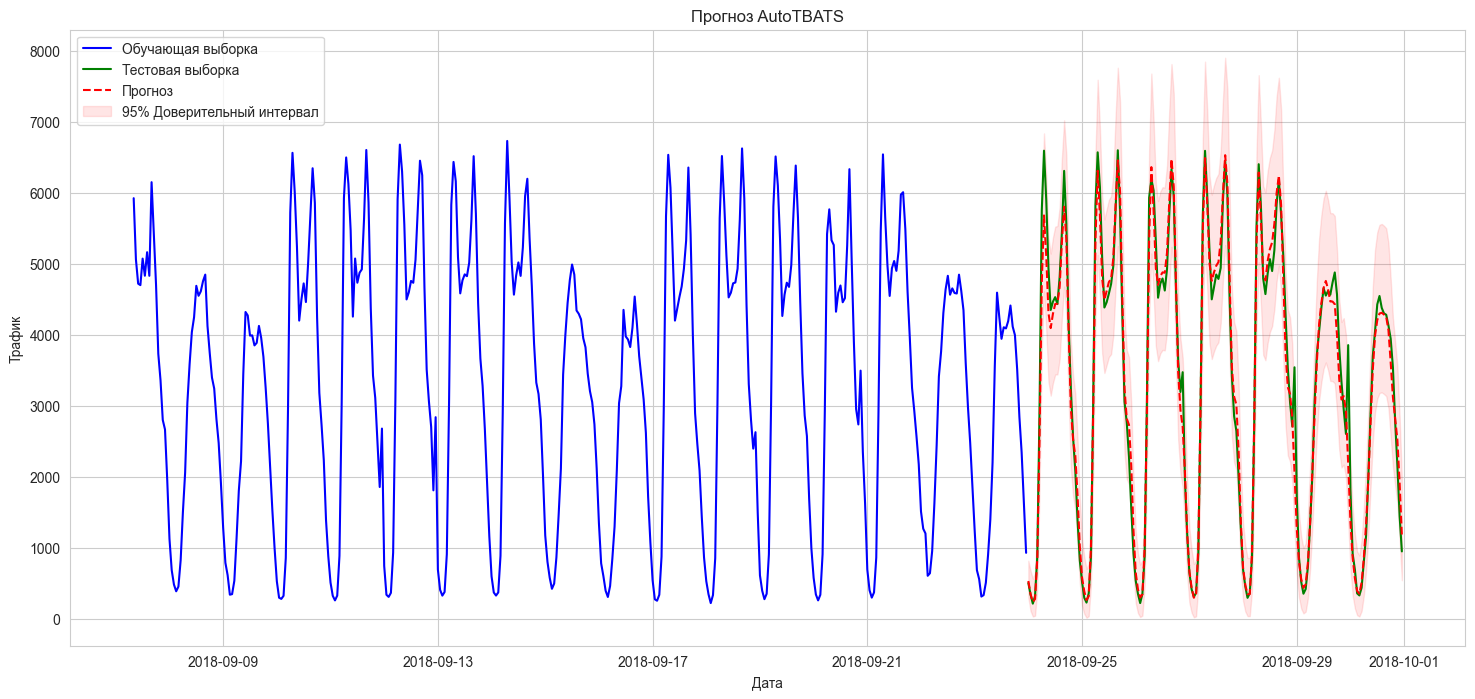

In [50]:
graph_show_fc(y_pred.set_index('ds'), "AutoTBATS")